In [1]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT = Path.cwd().parent
PROCESSED = PROJECT / "data" / "processed"
FIGS = PROJECT / "figures"
TABLES = PROJECT / "tables"
TABLES.mkdir(exist_ok=True)

df = pd.read_csv(PROCESSED / "daily_dataset.csv", index_col="date", parse_dates=True)

EVENTS = {
    "Ukraine invasion (2022)":        "2022-02-24",
    "Hamas attack (Oct 2023)":        "2023-10-09",
    "Iran attack (Apr 2024)":         "2024-04-15",
    "Iran missiles (Oct 2024)":       "2024-10-01",
    "Israel strikes Iran (Jun 2025)": "2025-06-13",
    "US strikes Iran (Jun 2025)":     "2025-06-23",
    "US-Israel war on Iran (2026)":   "2026-03-02",
}
SHORT = {
    "Ukraine invasion (2022)": "Ukraine 22", "Hamas attack (Oct 2023)": "Hamas 23",
    "Iran attack (Apr 2024)": "Iran Apr 24", "Iran missiles (Oct 2024)": "Iran Oct 24",
    "Israel strikes Iran (Jun 2025)": "Israel Jun 25", "US strikes Iran (Jun 2025)": "US Jun 25",
    "US-Israel war on Iran (2026)": "Iran war 26",
}

WINDOWS = {
    "early [-60,-31]": (-60, -31),
    "late [-30,-6]":   (-30, -6),
    "onset [0,+1]":    (0, 1),
    "post [0,+5]":     (0, 5),
    "post [0,+10]":    (0, 10),
}
EST = (-250, -61)   # estimation window

In [2]:
def event_window(day0, pre=250, post=20):
    pos = df.index.get_loc(pd.Timestamp(day0))
    start = max(pos - pre, 0)
    w = df.iloc[start : pos + post + 1].copy()
    w["t"] = np.arange(len(w)) - (pos - start)
    return w

def abnormal_returns(day0, col="RET_GSPC", bench=None):
    """bench=None -> constant-mean model; bench='RET_ACWX' -> market model on that index."""
    w = event_window(day0)
    est = w[(w["t"] >= EST[0]) & (w["t"] <= EST[1])]
    est = est.dropna(subset=[col] + ([bench] if bench else []))

    if bench is None:
        mu = est[col].mean()
        w["AR"] = w[col] - mu
        sigma = est[col].std(ddof=1)
    else:
        beta, alpha = np.polyfit(est[bench], est[col], 1)
        w["AR"] = w[col] - (alpha + beta * w[bench])
        resid = est[col] - (alpha + beta * est[bench])
        sigma = resid.std(ddof=2)
    return w, sigma, len(est)

def car_stats(w, sigma, a, b):
    sel = w[(w["t"] >= a) & (w["t"] <= b)]["AR"].dropna()
    car = sel.sum()
    se = sigma * math.sqrt(len(sel))
    tstat = car / se
    p = math.erfc(abs(tstat) / math.sqrt(2))   # two-sided p-value (normal approximation)
    return car, se, tstat, p

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

In [3]:
rows = []
for bench_name, bench in [("constant mean", None), ("ACWX market model", "RET_ACWX")]:
    for ev, day0 in EVENTS.items():
        w, sigma, n_est = abnormal_returns(day0, bench=bench)
        for wname, (a, b) in WINDOWS.items():
            car, se, tstat, p = car_stats(w, sigma, a, b)
            rows.append({"benchmark": bench_name, "event": ev, "window": wname,
                         "CAR": car, "SE": se, "t": tstat, "p": p, "n_est": n_est})

res = pd.DataFrame(rows)
res.to_csv(TABLES / "event_study_cars.csv", index=False)

# readable table: CAR (%) with significance stars, constant-mean benchmark
def show(bench_name):
    r = res[res["benchmark"] == bench_name].copy()
    r["cell"] = r["CAR"].round(2).astype(str) + r["p"].apply(stars)
    t = r.pivot(index="event", columns="window", values="cell")
    return t.reindex(index=list(EVENTS), columns=list(WINDOWS))

print("CONSTANT-MEAN BENCHMARK  (CAR in %, * p<.10 ** p<.05 *** p<.01)")
display(show("constant mean"))
print("\nACWX MARKET MODEL  (US-specific part only)")
display(show("ACWX market model"))

CONSTANT-MEAN BENCHMARK  (CAR in %, * p<.10 ** p<.05 *** p<.01)


window,"early [-60,-31]","late [-30,-6]","onset [0,+1]","post [0,+5]","post [0,+10]"
event,,,,,
Ukraine invasion (2022),-1.32,-6.82*,3.5***,2.62,-0.28
Hamas attack (Oct 2023),-6.4,-4.86,0.92,0.82,-3.39
Iran attack (Apr 2024),5.12,0.31,-1.56,-2.66,-0.93
Iran missiles (Oct 2024),-4.35,-0.52,-1.2,-1.02,-0.6
Israel strikes Iran (Jun 2025),-1.37,5.97,-0.24,-0.44,2.4
US strikes Iran (Jun 2025),-3.4,6.38,2.01,3.73,3.91
US-Israel war on Iran (2026),-0.47,-2.02,-1.05,-1.64,-3.42



ACWX MARKET MODEL  (US-specific part only)


window,"early [-60,-31]","late [-30,-6]","onset [0,+1]","post [0,+5]","post [0,+10]"
event,,,,,
Ukraine invasion (2022),-2.81,-6.05***,2.84***,5.01***,4.25***
Hamas attack (Oct 2023),1.89,-0.89,0.1,0.81,0.07
Iran attack (Apr 2024),1.44,-1.48,-0.49,-2.31**,-2.02
Iran missiles (Oct 2024),-2.56,-0.66,-1.02,0.38,2.04
Israel strikes Iran (Jun 2025),-0.09,2.6,0.26,1.03,2.05
US strikes Iran (Jun 2025),-3.45,2.99,0.39,1.34,1.73
US-Israel war on Iran (2026),-4.14,-5.52,4.42***,5.0***,4.39*


In [4]:
for wname in ["early [-60,-31]", "late [-30,-6]"]:
    r = res[(res["benchmark"] == "constant mean") & (res["window"] == wname)]
    mean_car = r["CAR"].mean()
    se_mean = math.sqrt((r["SE"] ** 2).sum()) / len(r)   # assumes events are independent
    tstat = mean_car / se_mean
    p = math.erfc(abs(tstat) / math.sqrt(2))
    print(f"{wname:16s} mean CAR = {mean_car:6.2f}%   t = {tstat:5.2f}   p = {p:.3f}")

early [-60,-31]  mean CAR =  -1.74%   t = -0.90   p = 0.370
late [-30,-6]    mean CAR =  -0.22%   t = -0.12   p = 0.901


In [5]:
exp_rows = []
for ev, day0 in EVENTS.items():
    w = event_window(day0)
    pre = w[(w["t"] >= -20) & (w["t"] <= -6)]["GPRD_THREAT"].mean()
    normal = w[(w["t"] >= EST[0]) & (w["t"] <= EST[1])]["GPRD_THREAT"].mean()
    exp_rows.append({"event": ev, "log_buildup": np.log(pre / normal)})
expect = pd.DataFrame(exp_rows).set_index("event")

cm = res[res["benchmark"] == "constant mean"].pivot(index="event", columns="window", values="CAR")
h2 = expect.join(cm)

for wname in ["onset [0,+1]", "post [0,+5]", "post [0,+10]"]:
    r = h2["log_buildup"].corr(h2[wname])
    slope, intercept = np.polyfit(h2["log_buildup"], h2[wname], 1)
    print(f"{wname:13s} corr = {r:5.2f}   slope = {slope:5.2f} pp per log-unit of build-up")

# episode-level version: average the two June 2025 shocks into one observation
ep = h2.copy()
jun = ["Israel strikes Iran (Jun 2025)", "US strikes Iran (Jun 2025)"]
ep.loc["Jun 2025 (episode)"] = ep.loc[jun].mean()
ep = ep.drop(index=jun)
print("\nEpisode-level (6 episodes), onset [0,+1] corr =",
      round(ep["log_buildup"].corr(ep["onset [0,+1]"]), 2))

h2.to_csv(TABLES / "h2_buildup_vs_car.csv")

onset [0,+1]  corr =  0.85   slope =  3.82 pp per log-unit of build-up
post [0,+5]   corr =  0.74   slope =  4.05 pp per log-unit of build-up
post [0,+10]  corr =  0.53   slope =  3.44 pp per log-unit of build-up

Episode-level (6 episodes), onset [0,+1] corr = 0.95


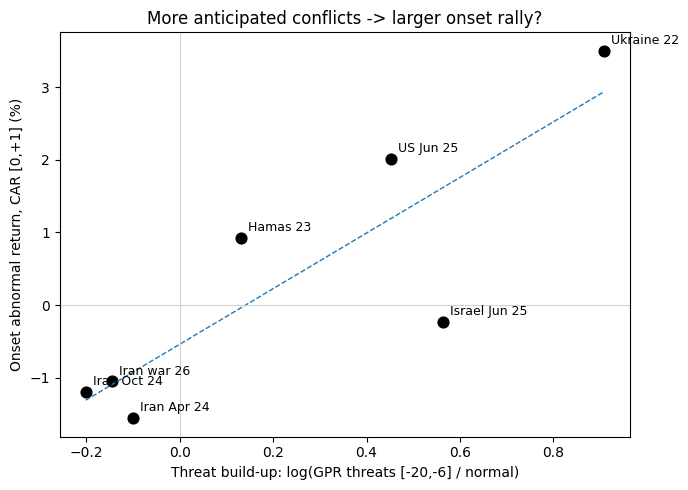

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
x, y = h2["log_buildup"], h2["onset [0,+1]"]
ax.scatter(x, y, s=60, color="black")
for ev in h2.index:
    ax.annotate(SHORT[ev], (x[ev], y[ev]), xytext=(5, 5), textcoords="offset points", fontsize=9)

slope, intercept = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, intercept + slope * xs, color="tab:blue", lw=1, ls="--")

ax.axhline(0, color="lightgrey", lw=0.8)
ax.axvline(0, color="lightgrey", lw=0.8)
ax.set_xlabel("Threat build-up: log(GPR threats [-20,-6] / normal)")
ax.set_ylabel("Onset abnormal return, CAR [0,+1] (%)")
ax.set_title("More anticipated conflicts -> larger onset rally?")
plt.tight_layout()
plt.savefig(FIGS / "02_h2_buildup_vs_onset.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
def corr_xy(d, x="log_buildup", y="onset [0,+1]"):
    return d[x].corr(d[y])

print(f"All 7 events:            corr = {corr_xy(h2):5.2f}")
for ev in h2.index:
    print(f"  drop {SHORT[ev]:14s}     corr = {corr_xy(h2.drop(index=ev)):5.2f}")

print(f"\nAll 6 episodes:          corr = {corr_xy(ep):5.2f}")
for ev in ep.index:
    print(f"  drop {SHORT.get(ev, ev):18s} corr = {corr_xy(ep.drop(index=ev)):5.2f}")

All 7 events:            corr =  0.85
  drop Ukraine 22         corr =  0.70
  drop Hamas 23           corr =  0.88
  drop Iran Apr 24        corr =  0.83
  drop Iran Oct 24        corr =  0.83
  drop Israel Jun 25      corr =  0.97
  drop US Jun 25          corr =  0.85
  drop Iran war 26        corr =  0.84

All 6 episodes:          corr =  0.95
  drop Ukraine 22         corr =  0.85
  drop Hamas 23           corr =  0.98
  drop Iran Apr 24        corr =  0.96
  drop Iran Oct 24        corr =  0.94
  drop Iran war 26        corr =  0.94
  drop Jun 2025 (episode) corr =  0.97


In [8]:
def buildup_measures(day0):
    w = event_window(day0)
    t = w["t"]
    def m(s, a, b):
        return s[(t >= a) & (t <= b)].mean()
    th, ac, tot = w["GPRD_THREAT"], w["GPRD_ACT"], w["GPRD"]
    lth = np.log1p(th)
    est_sd = lth[(t >= EST[0]) & (t <= EST[1])].std()
    return {
        "threat ratio [-20,-6] (main)":       np.log(m(th, -20, -6) / m(th, *EST)),
        "threat z-score [-20,-6]":            (m(lth, -20, -6) - m(lth, *EST)) / est_sd,
        "threat ratio [-30,-6]":              np.log(m(th, -30, -6) / m(th, *EST)),
        "threat ratio [-10,-1]":              np.log(m(th, -10, -1) / m(th, *EST)),
        "threat trend [-10,-6] vs [-20,-16]": m(lth, -10, -6) - m(lth, -20, -16),
        "total GPR ratio [-20,-6]":           np.log(m(tot, -20, -6) / m(tot, *EST)),
        "ACTS ratio [-20,-6] (falsification)": np.log(m(ac, -20, -6) / m(ac, *EST)),
    }

meas = pd.DataFrame({ev: buildup_measures(d) for ev, d in EVENTS.items()}).T
alt = meas.join(cm[["onset [0,+1]", "post [0,+5]"]])

rows = []
for col in meas.columns:
    loo = [alt.drop(index=ev)[col].corr(alt.drop(index=ev)["onset [0,+1]"]) for ev in alt.index]
    rows.append({"measure": col,
                 "corr onset [0,+1]": alt[col].corr(alt["onset [0,+1]"]),
                 "corr post [0,+5]":  alt[col].corr(alt["post [0,+5]"]),
                 "lowest leave-one-out (onset)": min(loo)})
robust = pd.DataFrame(rows).set_index("measure").round(2)
display(robust)
robust.to_csv(TABLES / "h2_alt_measures.csv")

,"corr onset [0,+1]","corr post [0,+5]",lowest leave-one-out (onset)
measure,,,
"threat ratio [-20,-6] (main)",0.85,0.74,0.70
"threat z-score [-20,-6]",0.79,0.71,0.64
"threat ratio [-30,-6]",0.84,0.73,0.66
"threat ratio [-10,-1]",0.76,0.68,0.48
"threat trend [-10,-6] vs [-20,-16]",-0.54,-0.47,-0.68
"total GPR ratio [-20,-6]",0.80,0.63,0.53
"ACTS ratio [-20,-6] (falsification)",0.14,0.06,-0.13


In [9]:
from itertools import permutations

def perm_pvalue(d, x="log_buildup", y="onset [0,+1]"):
    xv, yv = d[x].values, d[y].values
    obs = np.corrcoef(xv, yv)[0, 1]
    rs = np.array([np.corrcoef(xv, np.array(p))[0, 1] for p in permutations(yv)])
    return obs, np.mean(rs >= obs - 1e-12), len(rs)

for label, d in [("7 events", h2), ("6 episodes", ep)]:
    obs, p, n = perm_pvalue(d)
    print(f"{label:10s} corr = {obs:.2f}   permutation p = {p:.4f}   ({n} orderings)")

7 events   corr = 0.85   permutation p = 0.0129   (5040 orderings)
6 episodes corr = 0.95   permutation p = 0.0153   (720 orderings)


Across 1,000 random non-event days: corr(build-up, onset CAR) = -0.121
Real corr = 0.85;  share of fake 7-day studies with corr >= real: 0.0054


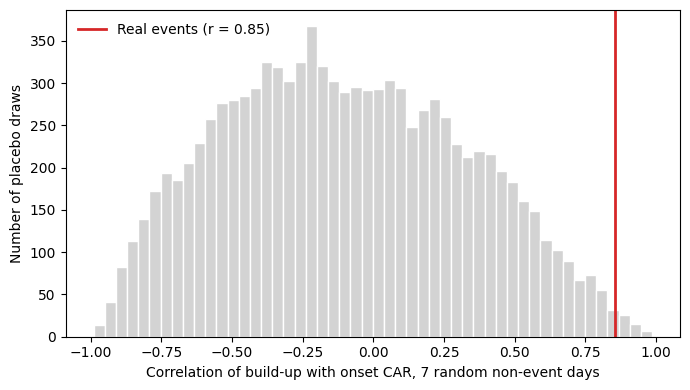

In [10]:
rng = np.random.default_rng(42)
event_pos = [df.index.get_loc(pd.Timestamp(d)) for d in EVENTS.values()]
eligible = [p for p in range(260, len(df) - 21)
            if min(abs(p - e) for e in event_pos) > 30]     # stay away from real events
pool_pos = rng.choice(eligible, size=1000, replace=False)

prow = []
for p in pool_pos:
    d0 = df.index[p]
    w, sigma, _ = abnormal_returns(d0)
    car, _, _, _ = car_stats(w, sigma, 0, 1)
    t = w["t"]
    pre = w.loc[(t >= -20) & (t <= -6), "GPRD_THREAT"].mean()
    normal = w.loc[(t >= EST[0]) & (t <= EST[1]), "GPRD_THREAT"].mean()
    prow.append({"date": d0, "log_buildup": np.log(pre / normal), "onset": car})
pool = pd.DataFrame(prow)

print(f"Across 1,000 random non-event days: corr(build-up, onset CAR) = "
      f"{pool['log_buildup'].corr(pool['onset']):.3f}")

# draw 10,000 fake 'studies' of 7 random days each
obs = corr_xy(h2)
sims = np.array([pool.sample(7, random_state=i)[["log_buildup", "onset"]].corr().iloc[0, 1]
                 for i in range(10_000)])
p_placebo = np.mean(sims >= obs)
print(f"Real corr = {obs:.2f};  share of fake 7-day studies with corr >= real: {p_placebo:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(sims, bins=50, color="lightgrey", edgecolor="white")
ax.axvline(obs, color="tab:red", lw=2, label=f"Real events (r = {obs:.2f})")
ax.set_xlabel("Correlation of build-up with onset CAR, 7 random non-event days")
ax.set_ylabel("Number of placebo draws")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGS / "03_h2_placebo.png", dpi=200, bbox_inches="tight")
plt.show()